# Week 3 · A First Classifier: Logistic Regression on the MAGIC Telescope Data

**AI SCI 290A, Tuesday of Week 3**

Last Thursday you wrote a rule by hand to tell penguin species apart. Today the computer finds the rule. We will:

1. Load a data file that has no column names
2. Look at the features, separated by class
3. Try a one-feature rule as a baseline
4. Split the data into a training set and a test set
5. Standardize the features
6. Train a logistic regression
7. Measure it: accuracy, confusion matrix, threshold, ROC curve and AUC
8. See which features the model relies on

**The data:** the MAGIC gamma-ray telescope dataset (UCI Machine Learning Repository). When a high-energy particle hits the atmosphere it makes a shower of light, which a telescope camera records as an elliptical image. The task is to tell **gamma-ray** showers (signal) from showers caused by **hadrons**, mostly protons (background). The events were simulated by the MAGIC collaboration.

**Before you start:** your folder should look like this:
```
290A/week3/
├── week3_logistic_magic.ipynb   ← this notebook
└── data/
    └── magic04.data
```

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_FILE = Path("data/magic04.data")
print("Notebook is running in:", Path.cwd())
print("Data file", "found" if DATA_FILE.exists() else "NOT FOUND: check the folder layout above")

Notebook is running in: /Users/jesse/290A/week3
Data file found


## 1. Load a file with no column names

Open `magic04.data` in a text editor and look at the first line:

```
28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.011,-8.2027,40.092,81.8828,g
```

There is no header row: the file starts with data. The column names are listed separately, on the dataset's web page. We pass them to pandas with `names=`.

In [2]:
FEATURES = ["fLength", "fWidth", "fSize", "fConc", "fConc1",
            "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist"]

df = pd.read_csv(DATA_FILE, names=FEATURES + ["class"])
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


Try it: remove `names=FEATURES + ["class"]` and run the cell again. What does pandas use as column names?

What the features mean:

| Column | Meaning |
|---|---|
| fLength, fWidth | Length and width of the shower image (mm) |
| fSize | Total brightness of the image (log of the summed light) |
| fConc, fConc1 | How concentrated the light is in the brightest 2 pixels, or the brightest 1 |
| fAsym | How lopsided the light is along the image's long axis (mm) |
| fM3Long, fM3Trans | Skewness of the light along and across the long axis (mm) |
| fAlpha | Angle between the image's long axis and the direction to the camera center (degrees) |
| fDist | Distance from the camera center to the image center (mm) |

The `class` column holds the letters `g` (gamma) and `h` (hadron). Models need numbers, so we make a `label` column: **1 for gamma, 0 for hadron**.

In [3]:
df["class"].value_counts()

class
g    12332
h     6688
Name: count, dtype: int64

In [4]:
df["label"] = (df["class"] == "g").astype(int)
df[["class", "label"]].head()

,class,label
0,g,1
1,g,1
2,g,1
3,g,1
4,g,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19020 entries, 0 to 19019
Data columns (total 12 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   fLength   19020 non-null  float64
 1   fWidth    19020 non-null  float64
 2   fSize     19020 non-null  float64
 3   fConc     19020 non-null  float64
 4   fConc1    19020 non-null  float64
 5   fAsym     19020 non-null  float64
 6   fM3Long   19020 non-null  float64
 7   fM3Trans  19020 non-null  float64
 8   fAlpha    19020 non-null  float64
 9   fDist     19020 non-null  float64
 10  class     19020 non-null  object 
 11  label     19020 non-null  int64  
dtypes: float64(10), int64(1), object(1)
memory usage: 1.7+ MB


No missing values, and all features are numbers. The classes are **not** balanced:

In [6]:
print("Fraction of gammas:", round(df["label"].mean(), 3))

Fraction of gammas: 0.648


About 65% of events are gammas. Remember this number: a "model" that always says gamma would be right 65% of the time.

## 2. Look at the features, separated by class

The same plot as last Thursday: one histogram per class, per feature.

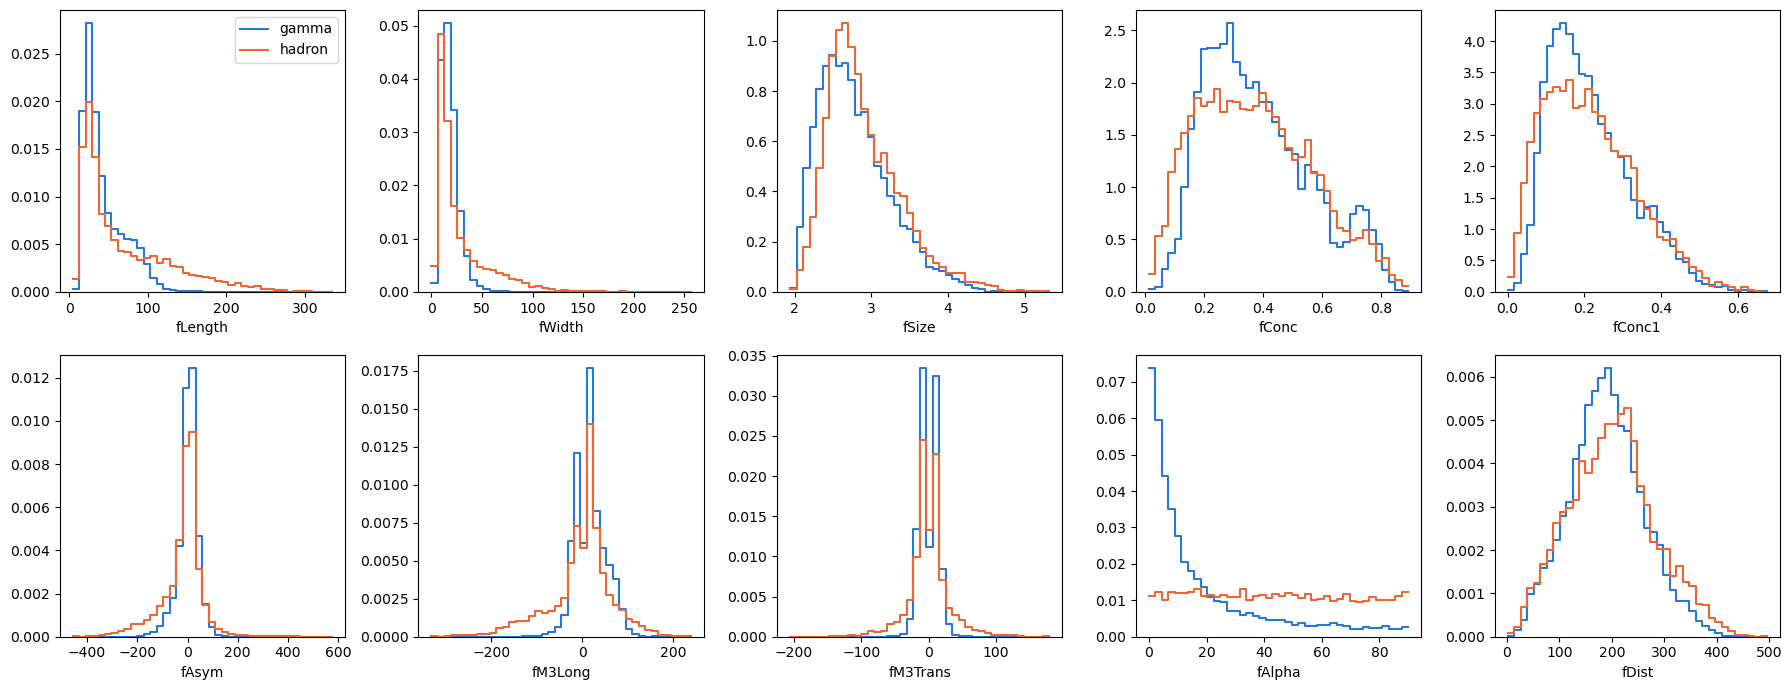

In [7]:
COLORS = {1: "#2a78d6", 0: "#eb6834"}
NAMES = {1: "gamma", 0: "hadron"}

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(data=df, x=col, hue="label", palette=COLORS, bins=40, stat="density",
                 common_norm=False, element="step", fill=False, lw=1.5, ax=ax)
    ax.get_legend().remove()
    ax.set_ylabel("")
axes[0, 0].legend(handles=[plt.Line2D([], [], color=COLORS[k], label=NAMES[k]) for k in (1, 0)])
plt.tight_layout()
plt.show()

**Question:** which single feature separates gammas from hadrons best?

`fAlpha` stands out. Gamma rays come from the source the telescope is pointed at, so their shower images point back toward the center of the camera: alpha is small. Hadrons arrive from all directions, so their alpha is spread out.

## 3. A one-feature rule as a baseline

Before training anything, try the simplest rule: **call it a gamma if alpha is small**. How good is it?

In [8]:
always_gamma = df["label"].mean()
print("Always say gamma:", round(always_gamma, 3))

for cut in [10, 20, 30]:
    guess = (df["fAlpha"] < cut).astype(int)
    accuracy = (guess == df["label"]).mean()
    print(f"Gamma if alpha < {cut}:  accuracy {accuracy:.3f}")

Always say gamma: 0.648
Gamma if alpha < 10:  accuracy 0.641
Gamma if alpha < 20:  accuracy 0.716
Gamma if alpha < 30:  accuracy 0.737


The alpha rule beats always guessing gamma, but not by much. Any model we train has to beat **both** of these numbers to be worth anything.

## 4. Split into training and test sets

If we test a model on the same events it learned from, we can't tell whether it learned the pattern or just memorized the events. So we hold back a **test set** that the model never sees during training.

- `test_size=0.25` keeps 25% of events for testing
- `stratify=y` keeps the same gamma fraction in both sets
- `random_state=42` makes the random split the same every time you run it

In [9]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print("Training events:", len(X_train))
print("Test events:    ", len(X_test))
print("Gamma fraction, train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Training events: 14265
Test events:     4755
Gamma fraction, train: 0.648  test: 0.648


## 5. Standardize the features

The features have very different scales: `fConc` is between 0 and 1, `fDist` goes up to about 500. Standardizing shifts and scales each feature to have **mean 0 and standard deviation 1**. That makes training work better, and it lets us compare the model's weights in Section 8.

Fit the scaler on the **training set only**, then apply it to both sets. If the test set helped choose the scaling, information from it would leak into training.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

Z_train = scaler.transform(X_train)
Z_test = scaler.transform(X_test)

print("Training means after scaling:", Z_train.mean(axis=0).round(2))
print("Training std devs after scaling:", Z_train.std(axis=0).round(2))

Training means after scaling: [ 0. -0.  0.  0.  0. -0.  0. -0.  0.  0.]
Training std devs after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. Train a logistic regression

Logistic regression computes a weighted sum of the features,

$$ s = w_1 x_1 + w_2 x_2 + \dots + w_{10} x_{10} + b, $$

and turns it into a probability between 0 and 1 with the S-shaped curve $p = 1/(1 + e^{-s})$. Training chooses the weights $w$ and the offset $b$ that best match the labels.

Every scikit-learn model uses the same three steps:

- `model.fit(X, y)` trains it
- `model.predict(X)` gives a class, 0 or 1
- `model.predict_proba(X)` gives the probability of each class

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(Z_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [12]:
# Predicted classes for the first 10 test events, next to the truth
pred = model.predict(Z_test)
pd.DataFrame({"true": y_test.values[:10], "predicted": pred[:10]})

,true,predicted
0,1,1
1,0,0
2,1,1
3,1,1
4,1,0
5,1,1
6,1,1
7,1,1
8,1,0
9,1,1


In [13]:
# Probability of being a gamma, for the same 10 events
prob = model.predict_proba(Z_test)[:, 1]   # column 1 = probability of class 1 (gamma)
prob[:10].round(3)

array([0.753, 0.166, 0.896, 0.826, 0.288, 0.816, 0.955, 0.854, 0.349,
       0.83 ])

## 7. How good is it?

### Accuracy

In [14]:
from sklearn.metrics import accuracy_score

print("Logistic regression:", round(accuracy_score(y_test, pred), 3))
print("Always say gamma:   ", round(y_test.mean(), 3))

Logistic regression: 0.783
Always say gamma:    0.648


### Confusion matrix

Accuracy hides *which* mistakes the model makes. The confusion matrix counts all four outcomes.

In [15]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred)
pd.DataFrame(cm, index=["true hadron", "true gamma"], columns=["called hadron", "called gamma"])

,called hadron,called gamma
true hadron,954,718
true gamma,315,2768


In physics we usually describe this with two numbers:

- **Signal efficiency:** the fraction of real gammas the model keeps
- **Background rejection:** the fraction of real hadrons the model throws out

In [16]:
tn, fp, fn, tp = cm.ravel()
print("Signal efficiency:    ", round(tp / (tp + fn), 3))
print("Background rejection: ", round(tn / (tn + fp), 3))

Signal efficiency:     0.898
Background rejection:  0.571


### Choosing a threshold

`predict` calls an event a gamma when its probability is above 0.5. That 0.5 is a choice. A higher threshold keeps fewer gammas but lets in fewer hadrons.

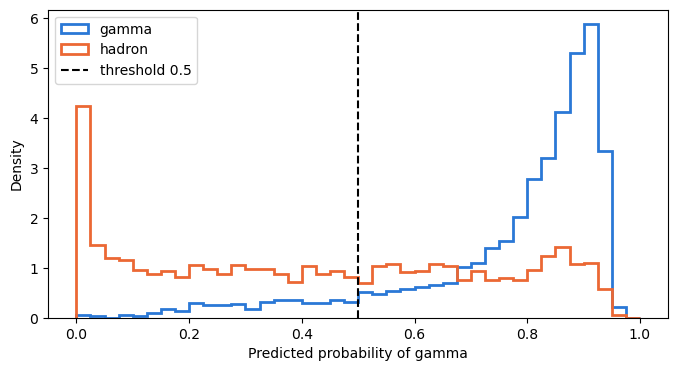

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 41)
ax.hist(prob[y_test == 1], bins=bins, histtype="step", lw=2, color=COLORS[1], label="gamma", density=True)
ax.hist(prob[y_test == 0], bins=bins, histtype="step", lw=2, color=COLORS[0], label="hadron", density=True)
ax.axvline(0.5, color="black", ls="--", label="threshold 0.5")
ax.set_xlabel("Predicted probability of gamma")
ax.set_ylabel("Density")
ax.legend()
plt.show()

In [18]:
for t in [0.3, 0.5, 0.7, 0.9]:
    called_gamma = prob > t
    eff = called_gamma[y_test == 1].mean()
    rej = 1 - called_gamma[y_test == 0].mean()
    print(f"threshold {t}:  signal efficiency {eff:.3f}   background rejection {rej:.3f}")

threshold 0.3:  signal efficiency 0.959   background rejection 0.390
threshold 0.5:  signal efficiency 0.898   background rejection 0.571
threshold 0.7:  signal efficiency 0.771   background rejection 0.758
threshold 0.9:  signal efficiency 0.235   background rejection 0.957


### ROC curve and AUC

The **ROC curve** shows every threshold at once: for each threshold, it plots the fraction of hadrons that pass (false positive rate) against the fraction of gammas that pass (true positive rate).

- A useless model sits on the diagonal
- A perfect model goes straight up the left side and along the top
- The **AUC** (area under the curve) summarizes it in one number: 0.5 is guessing, 1.0 is perfect

We compare the logistic regression with the alpha-only rule. For alpha, a *smaller* value means more gamma-like, so we use `-fAlpha` as its score.

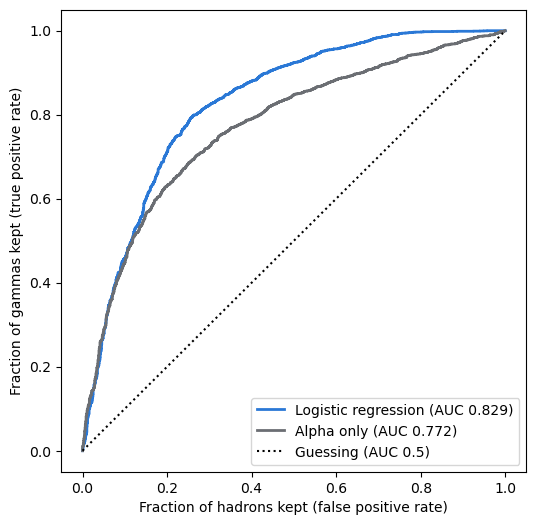

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_lr, tpr_lr, _ = roc_curve(y_test, prob)
fpr_a, tpr_a, _ = roc_curve(y_test, -X_test["fAlpha"])

auc_lr = roc_auc_score(y_test, prob)
auc_a = roc_auc_score(y_test, -X_test["fAlpha"])

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr_lr, tpr_lr, lw=2, color="#2a78d6", label=f"Logistic regression (AUC {auc_lr:.3f})")
ax.plot(fpr_a, tpr_a, lw=2, color="#6b6e73", label=f"Alpha only (AUC {auc_a:.3f})")
ax.plot([0, 1], [0, 1], "k:", label="Guessing (AUC 0.5)")
ax.set_xlabel("Fraction of hadrons kept (false positive rate)")
ax.set_ylabel("Fraction of gammas kept (true positive rate)")
ax.legend(loc="lower right")
plt.show()

## 8. What did the model learn?

Because the features were standardized, the weights are on the same scale. A large positive weight pushes events toward gamma; a large negative weight pushes toward hadron.

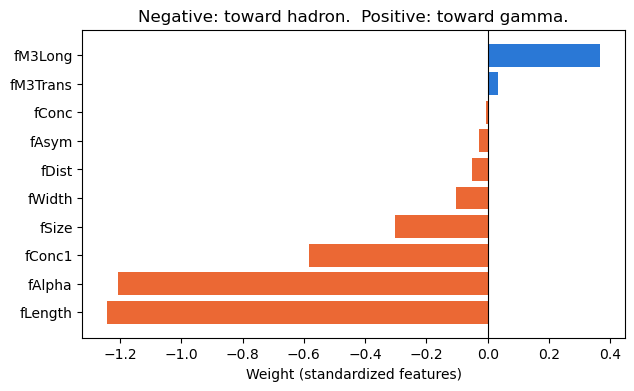

fLength    -1.24
fAlpha     -1.21
fConc1     -0.58
fSize      -0.30
fWidth     -0.10
fDist      -0.05
fAsym      -0.03
fConc      -0.01
fM3Trans    0.03
fM3Long     0.37
dtype: float64

In [20]:
weights = pd.Series(model.coef_[0], index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(weights.index, weights.values, color=["#eb6834" if w < 0 else "#2a78d6" for w in weights])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Weight (standardized features)")
ax.set_title("Negative: toward hadron.  Positive: toward gamma.")
plt.show()

weights.round(2)

**Question:** `fAlpha` has a large negative weight. Does that match what you saw in Section 2?

**Question:** in Section 2, `fWidth` separates the classes about as well as `fLength` (hadron images are both longer and wider). Yet `fLength` gets a large weight and `fWidth` almost none. Why? (Hint: run `df[["fLength", "fWidth"]].corr()`.)

**Caution:** weights are easy to over-read. When features are correlated, the model can split their effect between them in ways that are hard to interpret.

## 9. Exercises

1. Train a logistic regression on just **two** features: `fAlpha` plus one other. Which second feature helps most? How close does it get to the full model's AUC?
2. Find the threshold that keeps 90% of gammas. What fraction of hadrons gets through at that threshold? (Hint: `np.quantile(prob[y_test == 1], 0.10)`.)
3. Shuffle the labels before training with `np.random.default_rng(0).permutation(y_train)`, then train and evaluate as before. What AUC do you get, and why?
4. Change `random_state` in `train_test_split` to 0, 1, 2, 3 and 4. Retrain each time and record the AUC. How much does it change? What does that tell you about reporting an AUC to three decimal places?

In [25]:
# Exercise 1: alpha plus one other feature
results = {}
for other in FEATURES: 
    if other == "fAlpha": 
        continue 
    cols = ["fAlpha, fSize"]
    sc = StandardScaler().fit(X_train[cols])
    m = LogisticRegression().fit(sc.transform(X_train[cols], y_train))
    p = m.predict_prob(sc.transform(X_test[cols]))[:,1]
    results[other] = roc_auc_score(y_test, p)

pd.Series(results).sort_values(ascending=False).round(3)

KeyError: "None of [Index(['fAlpha, fSize'], dtype='object')] are in the [columns]"

In [ ]:
# Exercise 2

In [ ]:
# Exercise 3

In [ ]:
# Exercise 4